In [1]:
!pip install datasets

In [2]:
!pip install scikit-image -q

In [3]:
!pip install seaborn

In [4]:
import datasets
from datasets import load_dataset

ds = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:121: UserWarning: 
Access to the secret `HF_TOKEN` has not been granted on this notebook.
You will not be requested again.
Please restart the session if you want to be prompted again.
  warnings.warn(


README.md:   0%|          | 0.00/5.11k [00:00<?, ?B/s]

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  333MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  345MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (29 outputs left out)

data/test-00007-of-00008.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/42000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/45000 [00:00<?, ? examples/s]

In [5]:
# Ver los splits y features
print(ds.keys())
print(ds["train"].features)
print(ds["train"][0])  # primer ejemplo

dict_keys(['validation', 'train', 'test'])
{'Caption': Value('string'), 'Image': Image(mode=None, decode=True), 'Label_A': Value('int32'), 'Label_B': Value('int32')}
{'Caption': 'Two tall giraffe standing next to each other on a  field.', 'Image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x480 at 0x7B05840142F0>, 'Label_A': 0, 'Label_B': 0}


In [6]:
import pandas as pd

df = ds["train"].to_pandas()
print(df.shape)
df.head()

(42000, 4)


,Caption,Image,Label_A,Label_B
0,Two tall giraffe standing next to each other o...,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,0,0
1,Two tall giraffe standing next to each other o...,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1,1
2,Two tall giraffe standing next to each other o...,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1,2
3,Two tall giraffe standing next to each other o...,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1,3
4,Two tall giraffe standing next to each other o...,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1,4


['Caption', 'Image', 'Label_A', 'Label_B']


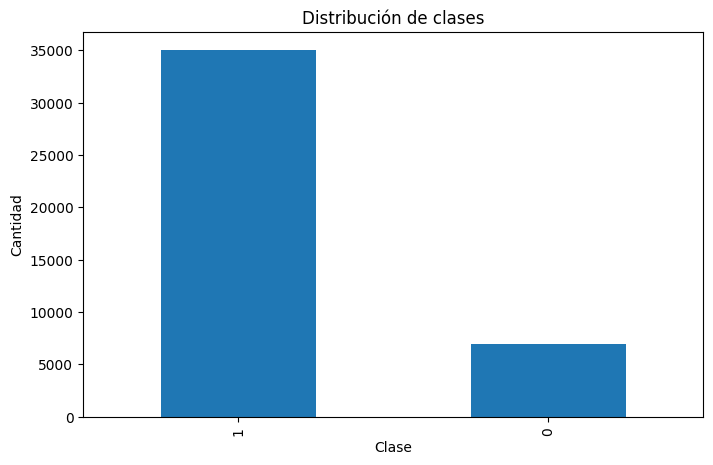

In [7]:
import matplotlib.pyplot as plt

# Ajusta 'label' al nombre real de la columna (revisa con df.columns)
print(df.columns.tolist())

df['Label_A'].value_counts()

df['Label_A'].value_counts().plot(kind='bar', figsize=(8,5))
plt.title("Distribución de clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.show()

['Caption', 'Image', 'Label_A', 'Label_B']


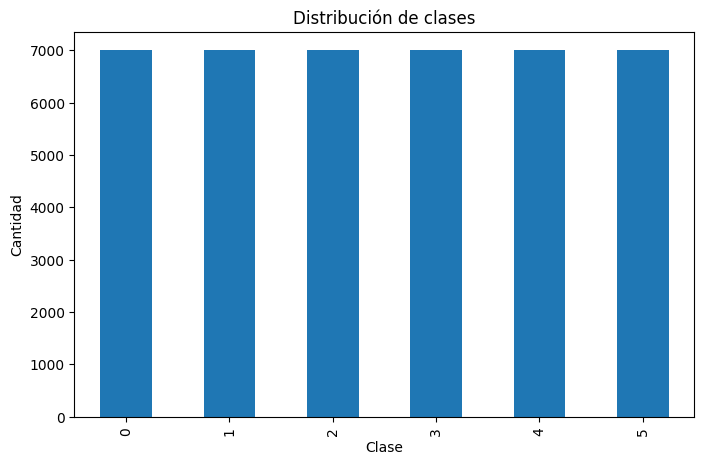

In [8]:
# Ajusta 'label' al nombre real de la columna (revisa con df.columns)
print(df.columns.tolist())

df['Label_B'].value_counts()

df['Label_B'].value_counts().plot(kind='bar', figsize=(8,5))
plt.title("Distribución de clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.show()

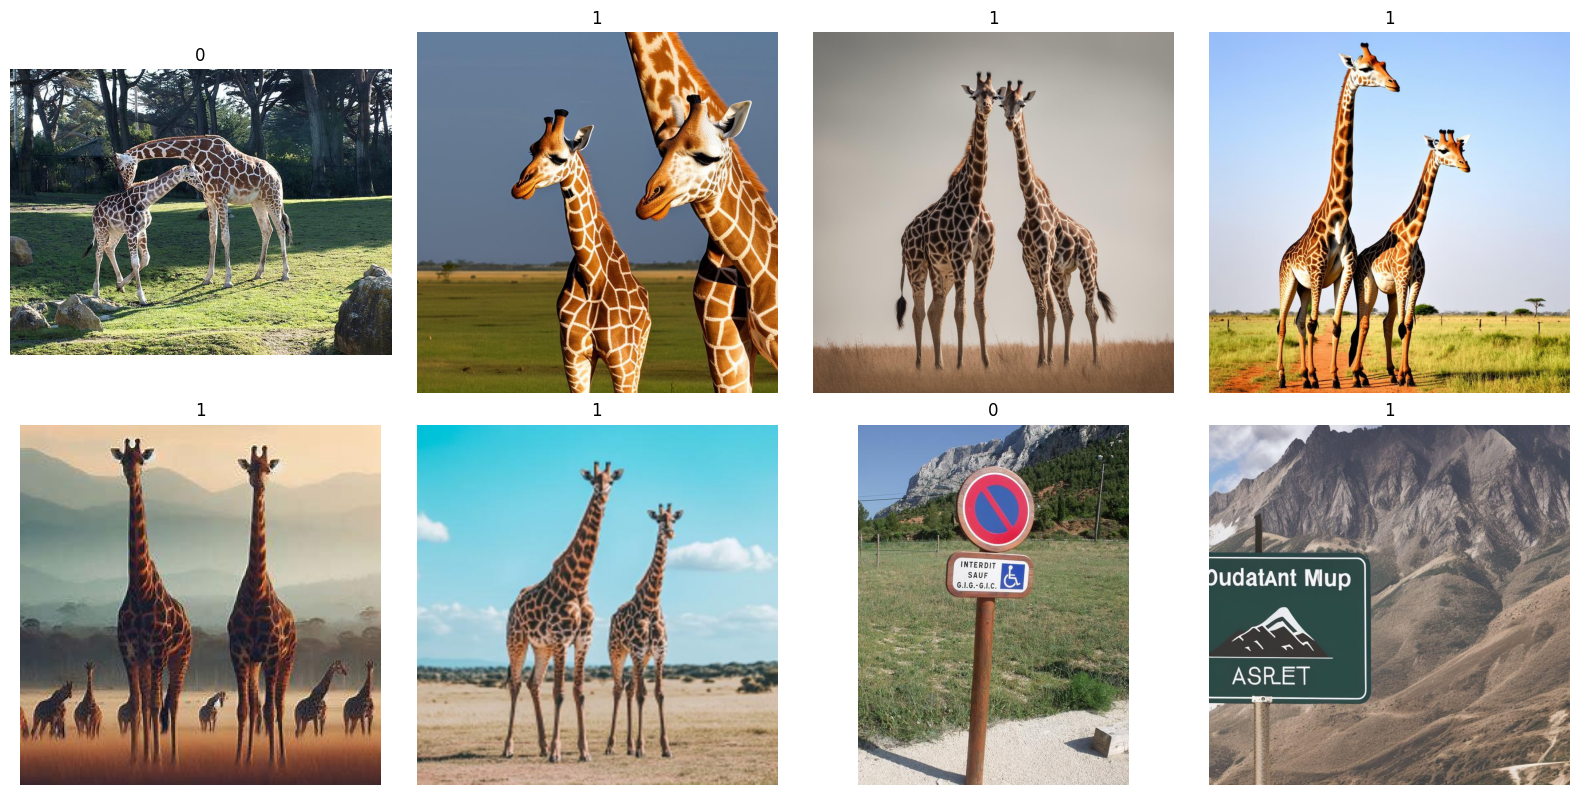

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    example = ds["train"][i]
    ax.imshow(example["Image"])  # ajusta el nombre de la columna de imagen
    ax.set_title(str(example.get("Label_A", "")))
    ax.axis("off")
plt.tight_layout()
plt.show()

Ancho - media: 684.03 min: 240 max: 1024
Alto  - media: 667.786 min: 213 max: 1024


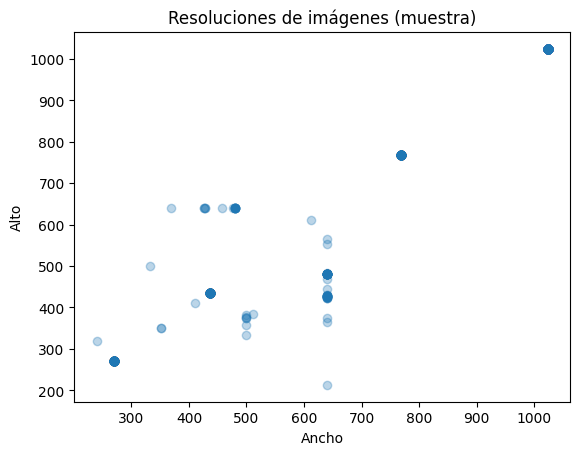

In [10]:
widths, heights = [], []
sample_size = min(500, len(ds["train"]))  # muestreo para no tardar mucho

for i in range(sample_size):
    img = ds["train"][i]["Image"]
    w, h = img.size
    widths.append(w)
    heights.append(h)

import numpy as np
print("Ancho - media:", np.mean(widths), "min:", min(widths), "max:", max(widths))
print("Alto  - media:", np.mean(heights), "min:", min(heights), "max:", max(heights))

plt.scatter(widths, heights, alpha=0.3)
plt.xlabel("Ancho")
plt.ylabel("Alto")
plt.title("Resoluciones de imágenes (muestra)")
plt.show()

In [11]:
for split in ds.keys():
    print(split, len(ds[split]))

validation 9000
train 42000
test 45000


In [12]:
import numpy as np
import pandas as pd
from PIL import Image
from scipy import stats
from skimage import color
from skimage.measure import shannon_entropy
from tqdm import tqdm

def extract_stats(img: Image.Image, source: str = None) -> dict:
    """Extrae estadísticas descriptivas de una imagen (Marco Teórico §1.1.2)."""
    img = np.array(img.convert('RGB')).astype(np.float32)
    H, W, _ = img.shape
    stats_dict = {'height': H, 'width': W}
    if source is not None:
        stats_dict['source'] = source

    for c, ch_name in enumerate(['R', 'G', 'B']):
        ch = img[:, :, c]
        stats_dict[f'mean_{ch_name}']     = ch.mean()                          # Eq. (1)
        stats_dict[f'std_{ch_name}']      = ch.std()                           # Eq. (2)
        stats_dict[f'kurtosis_{ch_name}'] = float(stats.kurtosis(ch.flatten()))  # κ
        stats_dict[f'skewness_{ch_name}'] = float(stats.skew(ch.flatten()))      # γ

    gray = color.rgb2gray(img / 255.0)
    stats_dict['entropy']    = shannon_entropy(gray)   # Eq. (3)
    stats_dict['brightness'] = gray.mean()
    stats_dict['contrast']   = gray.std()
    return stats_dict


# --- Separar índices por clase (ajusta 'label' y los valores reales según tus features) ---
train = ds["train"]
labels = train["Label_A"]  # lista/array de labels de todo el split

# Ajusta estos valores según cómo estén codificadas las clases en tu dataset
# (p. ej. 0/1, 'real'/'fake', etc. — revisa ds["train"].features['label'])
real_idx = [i for i, lab in enumerate(labels) if lab == 0]   # <-- ajustar
fake_idx = [i for i, lab in enumerate(labels) if lab == 1]   # <-- ajustar

print(f"Reales: {len(real_idx)} | Generadas: {len(fake_idx)}")

# --- Muestreo (ajusta N_SAMPLE según capacidad de cómputo) ---
N_SAMPLE = 500
sample_real_idx = np.random.choice(real_idx, min(N_SAMPLE, len(real_idx)), replace=False)
sample_fake_idx = np.random.choice(fake_idx, min(N_SAMPLE, len(fake_idx)), replace=False)

print('Extrayendo estadísticas — imágenes reales...')
stats_real = [extract_stats(train[int(i)]['Image']) for i in tqdm(sample_real_idx)]

print('Extrayendo estadísticas — imágenes generadas...')
stats_fake = [extract_stats(train[int(i)]['Image']) for i in tqdm(sample_fake_idx)]

df_real = pd.DataFrame(stats_real); df_real['label'] = 'Real'
df_fake = pd.DataFrame(stats_fake); df_fake['label'] = 'Fake'
df_all  = pd.concat([df_real, df_fake], ignore_index=True)

print('\nEstadísticas extraídas')
df_all.groupby('label')[['mean_R','mean_G','mean_B','entropy','brightness','contrast']].describe().round(3)

Reales: 7000 | Generadas: 35000
Extrayendo estadísticas — imágenes reales...


100%|██████████| 500/500 [00:08<00:00, 56.97it/s]


Extrayendo estadísticas — imágenes generadas...


100%|██████████| 500/500 [00:18<00:00, 27.12it/s]



Estadísticas extraídas


mean_R                                                               \
       count     mean     std     min      25%      50%      75%      max   
label                                                                       
Fake   500.0  124.738  27.730  27.386  109.672  124.326  140.801  247.301   
Real   500.0  115.739  30.182   9.449   96.842  115.504  132.725  242.045   

      mean_G           ... brightness        contrast                       \
       count     mean  ...        75%    max    count   mean    std    min   
label                  ...                                                   
Fake   500.0  119.600  ...      0.531  0.805    500.0  0.222  0.052  0.077   
Real   500.0  114.048  ...      0.504  0.888    500.0  0.240  0.057  0.043   

                                   
         25%    50%    75%    max  
label                              
Fake   0.187  0.220  0.257  0.389  
Real   0.207  0.241  0.279  0.406  

[2 rows x 48 columns]

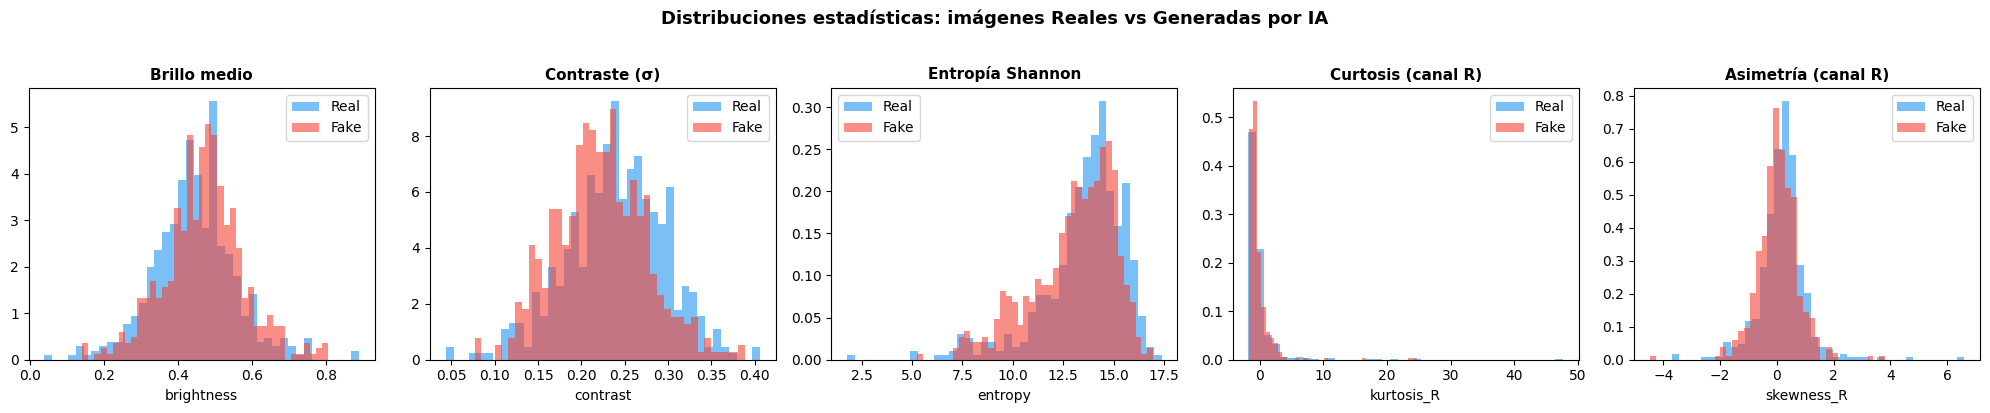

In [13]:
import matplotlib.pyplot as plt
import os

# Visualización de distribuciones por clase
features = ['brightness', 'contrast', 'entropy', 'kurtosis_R', 'skewness_R']
titles   = ['Brillo medio', 'Contraste (σ)', 'Entropía Shannon',
            'Curtosis (canal R)', 'Asimetría (canal R)']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, feat, title in zip(axes, features, titles):
    for label, color_ in [('Real', '#2196F3'), ('Fake', '#F44336')]:
        subset = df_all[df_all['label'] == label][feat].dropna()
        ax.hist(subset, bins=40, alpha=0.6, color=color_, label=label, density=True)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(feat)
    ax.legend()

fig.suptitle('Distribuciones estadísticas: imágenes Reales vs Generadas por IA',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()

# Carpeta de salida (ajusta la ruta si quieres guardarlo en otro lugar)
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/02_statistical_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

FFT Fake: 100%|██████████| 50/50 [00:00<00:00, 65.60it/s]


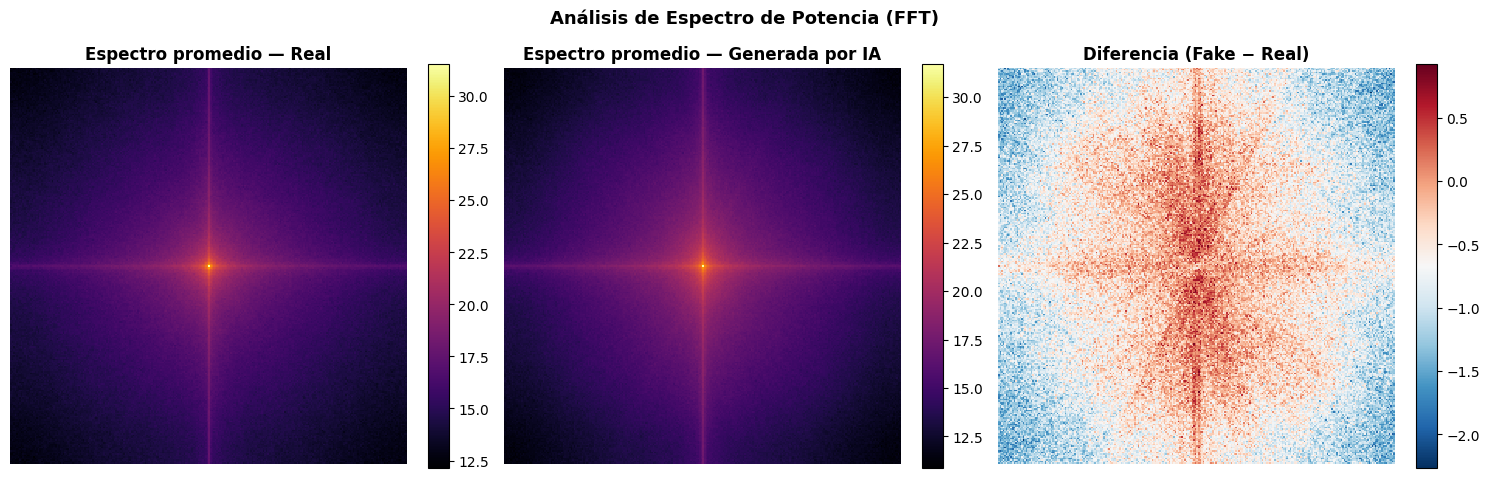

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from numpy.fft import fft2, fftshift
from tqdm import tqdm
import os

def compute_power_spectrum(img: Image.Image, size: int = 256) -> np.ndarray:
    """Calcula el espectro de potencia promediado sobre los 3 canales."""
    img = np.array(img.convert('RGB').resize((size, size)), dtype=np.float32)
    spectra = []
    for c in range(3):
        F  = fft2(img[:, :, c])          # DFT bidimensional
        Fs = fftshift(F)                  # centrar frecuencia cero
        P  = np.abs(Fs) ** 2              # espectro de potencia
        spectra.append(np.log1p(P))
    return np.mean(spectra, axis=0)


N_FFT = 50

ps_real = np.mean([
    compute_power_spectrum(train[int(i)]['Image'])
    for i in tqdm(sample_real_idx[:N_FFT], desc='FFT Real')
], axis=0)

ps_fake = np.mean([
    compute_power_spectrum(train[int(i)]['Image'])
    for i in tqdm(sample_fake_idx[:N_FFT], desc='FFT Fake')
], axis=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, ps, title in zip(axes[:2], [ps_real, ps_fake],
                         ['Espectro promedio — Real', 'Espectro promedio — Generada por IA']):
    im = ax.imshow(ps, cmap='inferno', interpolation='nearest')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046)

# Diferencia
diff = ps_fake - ps_real
im3 = axes[2].imshow(diff, cmap='RdBu_r', interpolation='nearest')
axes[2].set_title('Diferencia (Fake − Real)', fontsize=12, fontweight='bold')
axes[2].axis('off')
plt.colorbar(im3, ax=axes[2], fraction=0.046)

fig.suptitle('Análisis de Espectro de Potencia (FFT)',
             fontsize=13, fontweight='bold')
plt.tight_layout()

os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/04_power_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()

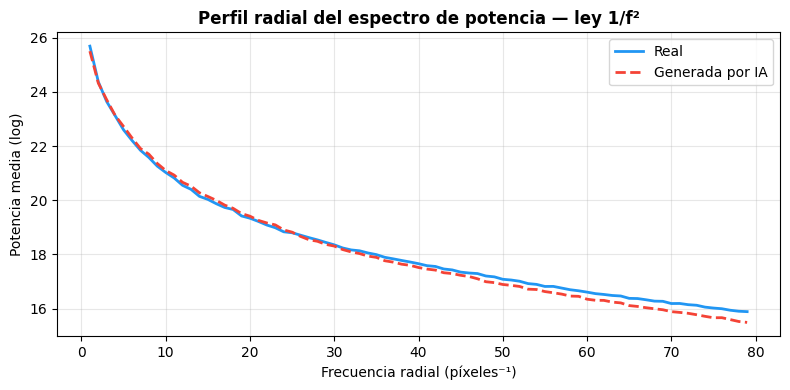

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ─── Perfil radial del espectro (ley 1/f²) ───────────────────────────────────
def radial_profile(data: np.ndarray) -> np.ndarray:
    """Perfil radial promediado del espectro de potencia."""
    y, x = np.indices(data.shape)
    center = np.array([(y.max() - y.min()) / 2.0, (x.max() - x.min()) / 2.0])
    r = np.sqrt((x - center[1])**2 + (y - center[0])**2).astype(int)
    tbin = np.bincount(r.ravel(), data.ravel())
    nr   = np.bincount(r.ravel())
    return tbin / (nr + 1e-8)

rp_real = radial_profile(ps_real)
rp_fake = radial_profile(ps_fake)
freqs   = np.arange(len(rp_real))

plt.figure(figsize=(8, 4))
plt.plot(freqs[1:80], rp_real[1:80], color='#2196F3', label='Real', linewidth=2)
plt.plot(freqs[1:80], rp_fake[1:80], color='#F44336', label='Generada por IA',
         linewidth=2, linestyle='--')
plt.xlabel('Frecuencia radial (píxeles⁻¹)')
plt.ylabel('Potencia media (log)')
plt.title('Perfil radial del espectro de potencia — ley 1/f²', fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/05_radial_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_846/81225945.py:39: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([var_real, var_fake], labels=['Real', 'Generada por IA'], patch_artist=True,


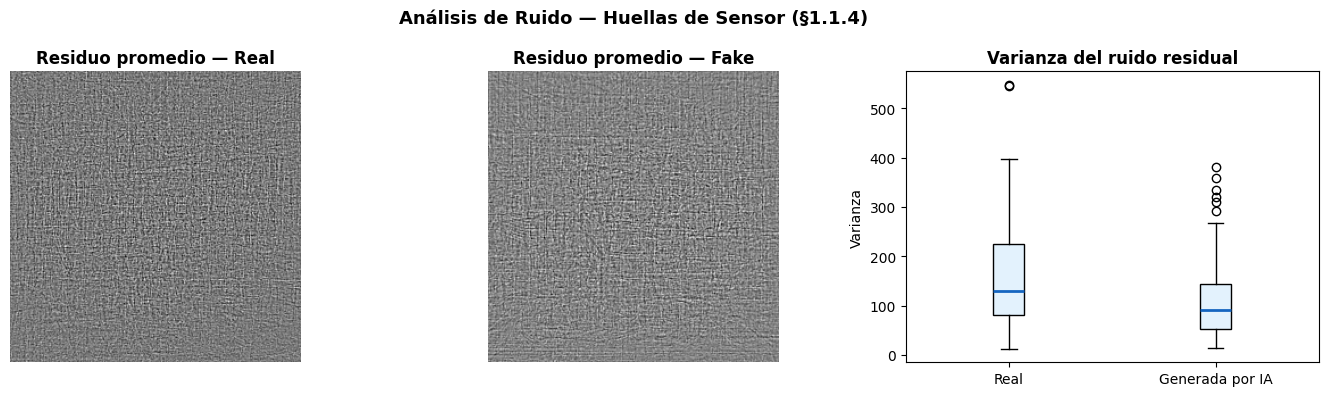

Varianza media ruido — Real: 160.0354  |  Fake: 111.9146
Test t: t=3.470, p=0.0006 — Diferencia significativa


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import uniform_filter
from scipy import stats
import os

def extract_noise_residual(img: Image.Image, size: int = 256) -> np.ndarray:
    """Extrae el residuo de ruido como diferencia entre imagen y versión suavizada."""
    img = np.array(img.convert('L').resize((size, size)), dtype=np.float32)
    smooth = uniform_filter(img, size=3)
    return img - smooth


N_NOISE = 100

noise_real = np.stack([
    extract_noise_residual(train[int(i)]['Image'])
    for i in sample_real_idx[:N_NOISE]
])
noise_fake = np.stack([
    extract_noise_residual(train[int(i)]['Image'])
    for i in sample_fake_idx[:N_NOISE]
])

# Varianza del ruido por imagen
var_real = noise_real.var(axis=(1, 2))
var_fake = noise_fake.var(axis=(1, 2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Residuo visual
axes[0].imshow(noise_real.mean(axis=0), cmap='gray')
axes[0].set_title('Residuo promedio — Real', fontweight='bold'); axes[0].axis('off')
axes[1].imshow(noise_fake.mean(axis=0), cmap='gray')
axes[1].set_title('Residuo promedio — Fake', fontweight='bold'); axes[1].axis('off')

# Comparación de varianza
axes[2].boxplot([var_real, var_fake], labels=['Real', 'Generada por IA'], patch_artist=True,
                boxprops=dict(facecolor='#E3F2FD'),
                medianprops=dict(color='#1565C0', linewidth=2))
axes[2].set_title('Varianza del ruido residual', fontweight='bold')
axes[2].set_ylabel('Varianza')

plt.suptitle('Análisis de Ruido — Huellas de Sensor (§1.1.4)', fontsize=13, fontweight='bold')
plt.tight_layout()

os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/06_noise_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Varianza media ruido — Real: {var_real.mean():.4f}  |  Fake: {var_fake.mean():.4f}')
t_stat, p_val = stats.ttest_ind(var_real, var_fake)
print(f'Test t: t={t_stat:.3f}, p={p_val:.4f} — {"Diferencia significativa" if p_val < 0.05 else "Sin diferencia significativa"}')

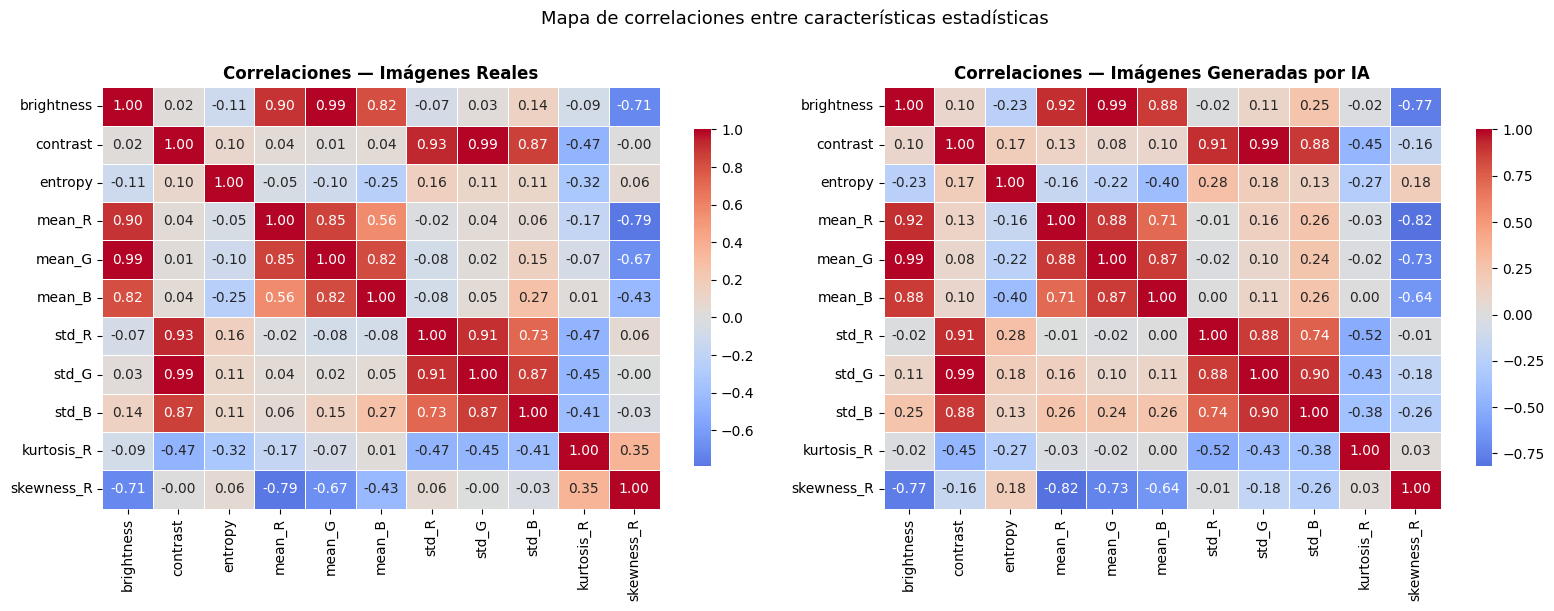

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

feat_cols = ['brightness', 'contrast', 'entropy', 'mean_R', 'mean_G', 'mean_B',
             'std_R', 'std_G', 'std_B', 'kurtosis_R', 'skewness_R']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, label, title in zip(axes, ['Real', 'Fake'],
                             ['Correlaciones — Imágenes Reales',
                              'Correlaciones — Imágenes Generadas por IA']):
    corr = df_all[df_all['label'] == label][feat_cols].corr()
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
                linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
    ax.set_title(title, fontsize=12, fontweight='bold')

plt.suptitle('Mapa de correlaciones entre características estadísticas', fontsize=13, y=1.01)
plt.tight_layout()

os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/07_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Análisis adicionales orientados al modelado con CNN (EfficientNet-B4) y ViT (ViT-B/16)

Las secciones anteriores cubren estadística descriptiva general (color, brillo, entropía, espectro FFT y ruido). Esta sección amplía el EDA con análisis pensados específicamente para las dos arquitecturas objetivo:

- **EfficientNet-B4** (entrada típica 380×380): CNN convolucional, muy sensible a textura local de alta frecuencia, artefactos de compresión y patrones periódicos de upsampling.
- **ViT-B/16** (entrada típica 224×224, parches de 16×16 → grilla 14×14): procesa la imagen como secuencia de parches, por lo que interesa la estadística *por parche*, no solo la global.

Se incluyen además dos verificaciones de higiene de datos que son prerrequisito antes de entrenar cualquiera de los dos modelos: **fuga de escenas repetidas** (mismo `Caption` con distinta etiqueta) y **atajos triviales de formato/compresión de archivo**.

### 8.1 Detección de fuga de datos por escena repetida (`Caption`)

Varias filas del dataset comparten el mismo `Caption` (p. ej. la escena de las jirafas) con distinto `Label_A`/`Label_B`, lo que sugiere que cada imagen real tiene "hermanas" sintéticas generadas a partir del mismo prompt/escena. Si esas variantes quedan repartidas entre train/val/test, un modelo (CNN o ViT) puede memorizar la escena en vez de aprender el patrón real-vs-fake. Primero se cuantifica esto **dentro** del split `train`; el cruce entre splits se revisa en la sección 8.9.

In [18]:
caption_group = df.groupby('Caption')['Label_A'].agg(['nunique', 'count'])
n_mixed = (caption_group['nunique'] > 1).sum()
n_total_captions = len(caption_group)

print(f"Captions únicos en train: {n_total_captions}")
print(f"Captions con imágenes de ambas clases (Real y Fake): {n_mixed} "
      f"({n_mixed / n_total_captions * 100:.1f}% de los captions)")
print("\nDistribución del número de imágenes por caption:")
print(caption_group['count'].describe())

# Ejemplo concreto de una escena compartida entre clases
example_caption = caption_group[caption_group['nunique'] > 1].index[0]
print(f"\nEjemplo — caption: \"{example_caption}\"")
print(df[df['Caption'] == example_caption][['Label_A', 'Label_B']].value_counts())

Captions únicos en train: 6948
Captions con imágenes de ambas clases (Real y Fake): 6948 (100.0% de los captions)

Distribución del número de imágenes por caption:
count    6948.000000
mean        6.044905
std         0.703892
min         6.000000
25%         6.000000
50%         6.000000
75%         6.000000
max        36.000000
Name: count, dtype: float64

Ejemplo — caption: " A bathroom with a toilet, sink, counter and large mirror"
Label_A  Label_B
0        0          1
1        1          1
         2          1
         3          1
         4          1
         5          1
Name: count, dtype: int64


### 8.2 Formato y compresión de archivo por clase (riesgo de atajo trivial)

Si las imágenes reales y las generadas difieren sistemáticamente en formato de archivo (JPEG vs. PNG), tamaño en disco o nivel de compresión JPEG, una CNN puede aprender a distinguir la clase a partir de artefactos de compresión en vez de contenido semántico — un **atajo (shortcut)** que no generaliza. Se usa `df['Image']` (bytes crudos, sin decodificar) obtenido en la celda 5, y un proxy de calidad JPEG a partir de la tabla de cuantización de luminancia (valores bajos ⇒ menor compresión ⇒ mayor calidad; esto es una heurística, no el valor exacto de "quality" usado al guardar el archivo).

In [19]:
import io
from PIL import Image as PILImage

def inspect_bytes(img_dict):
    b = img_dict['bytes']
    im = PILImage.open(io.BytesIO(b))
    fmt = im.format
    size_kb = len(b) / 1024
    quant_proxy = None
    if fmt == 'JPEG' and getattr(im, 'quantization', None):
        qt0 = im.quantization.get(0)
        if qt0:
            quant_proxy = float(np.mean(qt0))
    return pd.Series({'format': fmt, 'size_kb': size_kb, 'quant_proxy': quant_proxy})

N_FMT = 1000
sample_df = pd.concat([
    df[df['Label_A'] == 0].sample(min(N_FMT, (df['Label_A'] == 0).sum()), random_state=42),
    df[df['Label_A'] == 1].sample(min(N_FMT, (df['Label_A'] == 1).sum()), random_state=42),
]).copy()

sample_df[['format', 'size_kb', 'quant_proxy']] = sample_df['Image'].apply(inspect_bytes)
sample_df['clase'] = sample_df['Label_A'].map({0: 'Real', 1: 'Fake'})

print("Formato de archivo por clase:")
print(pd.crosstab(sample_df['clase'], sample_df['format']))

print("\nTamaño de archivo (KB) por clase:")
print(sample_df.groupby('clase')['size_kb'].describe().round(2))

print("\nProxy de calidad JPEG (tabla de cuantización; menor = más calidad):")
print(sample_df.groupby('clase')['quant_proxy'].describe().round(2))

Formato de archivo por clase:
format  JPEG
clase       
Fake    1000
Real    1000

Tamaño de archivo (KB) por clase:
        count   mean    std   min    25%    50%     75%     max
clase                                                          
Fake   1000.0  76.61  58.88  6.18  22.18  68.88  111.56  337.47
Real   1000.0  53.23  22.75  3.40  36.42  50.66   66.68  167.73

Proxy de calidad JPEG (tabla de cuantización; menor = más calidad):
        count   mean  std    min    25%    50%    75%    max
clase                                                       
Fake   1000.0  29.03  0.0  29.03  29.03  29.03  29.03  29.03
Real   1000.0  29.03  0.0  29.03  29.03  29.03  29.03  29.03


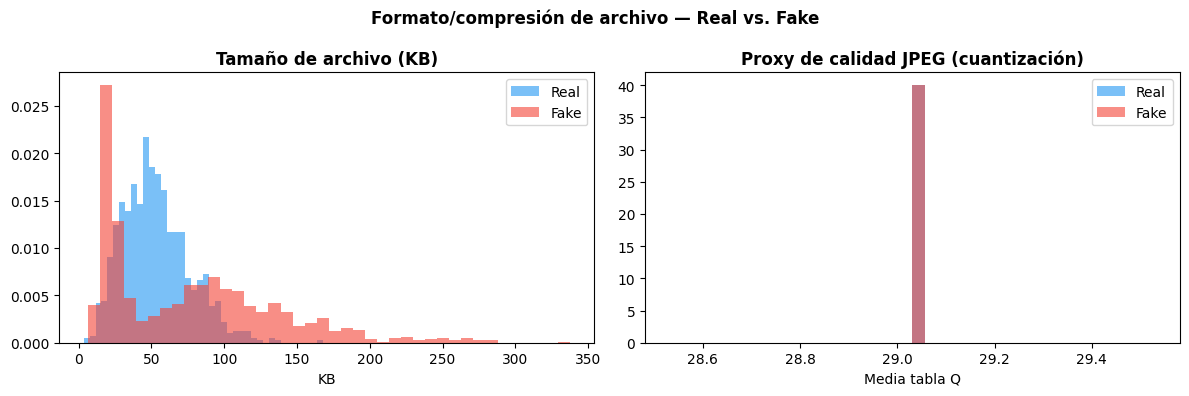

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color_ in [('Real', '#2196F3'), ('Fake', '#F44336')]:
    subset = sample_df[sample_df['clase'] == label]
    axes[0].hist(subset['size_kb'], bins=40, alpha=0.6, color=color_, label=label, density=True)
    axes[1].hist(subset['quant_proxy'].dropna(), bins=40, alpha=0.6, color=color_, label=label, density=True)
axes[0].set_title('Tamaño de archivo (KB)', fontweight='bold'); axes[0].set_xlabel('KB'); axes[0].legend()
axes[1].set_title('Proxy de calidad JPEG (cuantización)', fontweight='bold'); axes[1].set_xlabel('Media tabla Q'); axes[1].legend()
plt.suptitle('Formato/compresión de archivo — Real vs. Fake', fontweight='bold')
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/08_file_format_compression.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.3 Nitidez — Varianza del Laplaciano (señal de textura local para CNN)

Las CNN como EfficientNet-B4 son muy sensibles a la textura de alta frecuencia local. La varianza del filtro Laplaciano es un proxy estándar de "nitidez": imágenes con bordes muy definidos tienen varianza alta; imágenes suaves/borrosas (o con exceso de suavizado propio del proceso generativo), varianza baja.

Nitidez Fake: 100%|██████████| 300/300 [00:01<00:00, 164.65it/s]


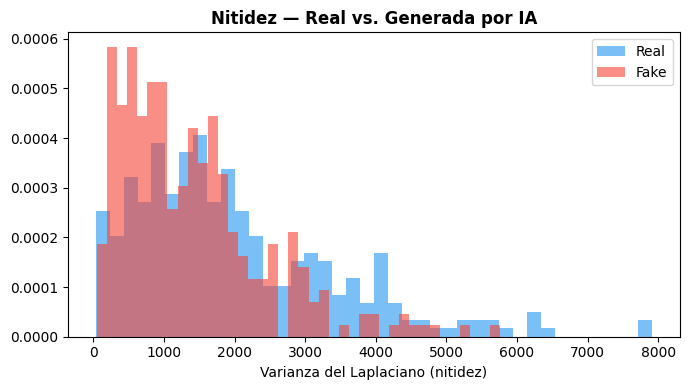

Nitidez media — Real: 2003.82 | Fake: 1392.46
Test t: t=5.968, p=0.0000 — Diferencia significativa


In [21]:
from scipy.ndimage import laplace

def sharpness_laplacian(img, size=256):
    g = np.array(img.convert('L').resize((size, size)), dtype=np.float32)
    return laplace(g).var()

N_SHARP = 300
sharp_real = [sharpness_laplacian(train[int(i)]['Image']) for i in tqdm(sample_real_idx[:N_SHARP], desc='Nitidez Real')]
sharp_fake = [sharpness_laplacian(train[int(i)]['Image']) for i in tqdm(sample_fake_idx[:N_SHARP], desc='Nitidez Fake')]

plt.figure(figsize=(7, 4))
plt.hist(sharp_real, bins=40, alpha=0.6, label='Real', color='#2196F3', density=True)
plt.hist(sharp_fake, bins=40, alpha=0.6, label='Fake', color='#F44336', density=True)
plt.xlabel('Varianza del Laplaciano (nitidez)')
plt.title('Nitidez — Real vs. Generada por IA', fontweight='bold')
plt.legend(); plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/09_sharpness_laplacian.png', dpi=150, bbox_inches='tight')
plt.show()

t_stat, p_val = stats.ttest_ind(sharp_real, sharp_fake)
print(f"Nitidez media — Real: {np.mean(sharp_real):.2f} | Fake: {np.mean(sharp_fake):.2f}")
print(f"Test t: t={t_stat:.3f}, p={p_val:.4f} — {'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia significativa'}")

### 8.4 Patrones periódicos tipo "checkerboard" (artefactos de upsampling)

El perfil radial promedio (sección 4.4) puede diluir picos espectrales puntuales característicos de convoluciones transpuestas / upsampling en GANs o difusión. Aquí se buscan picos de energía espectral **fuera** de la región de bajas frecuencias (excluyendo un radio central) en cada imagen individual, en lugar de solo en el promedio.

Picos Fake: 100%|██████████| 200/200 [00:01<00:00, 122.32it/s]
/tmp/ipykernel_846/2398416377.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([peak_real, peak_fake], labels=['Real', 'Fake'], patch_artist=True,


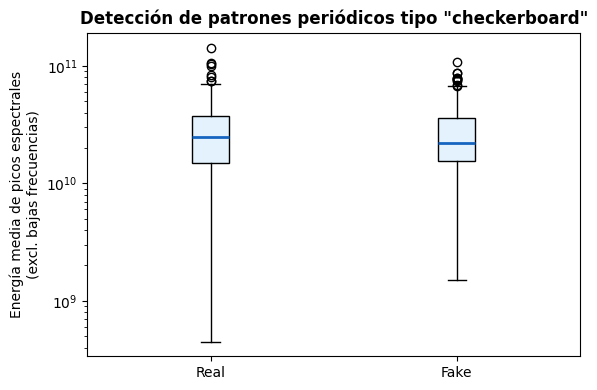

Picos espectrales (log1p) — Real: 28887568384.00 | Fake: 28304924672.00
Test t: t=-0.349, p=0.7274 — Sin diferencia significativa


In [22]:
def detect_periodic_peaks(img, size=256, exclude_radius=10, top_k=5):
    g = np.array(img.convert('L').resize((size, size)), dtype=np.float32)
    F = fftshift(fft2(g))
    P = np.abs(F) ** 2
    cy, cx = size // 2, size // 2
    Y, X = np.indices(P.shape)
    R = np.sqrt((X - cx) ** 2 + (Y - cy) ** 2)
    P_masked = P.copy()
    P_masked[R < exclude_radius] = 0  # excluir el pico DC / bajas frecuencias
    top_vals = np.sort(P_masked.ravel())[::-1][:top_k]
    return top_vals.mean()

N_PEAK = 200
peak_real = [detect_periodic_peaks(train[int(i)]['Image']) for i in tqdm(sample_real_idx[:N_PEAK], desc='Picos Real')]
peak_fake = [detect_periodic_peaks(train[int(i)]['Image']) for i in tqdm(sample_fake_idx[:N_PEAK], desc='Picos Fake')]

plt.figure(figsize=(6, 4))
plt.boxplot([peak_real, peak_fake], labels=['Real', 'Fake'], patch_artist=True,
            boxprops=dict(facecolor='#E3F2FD'), medianprops=dict(color='#1565C0', linewidth=2))
plt.ylabel('Energía media de picos espectrales\n(excl. bajas frecuencias)')
plt.yscale('log')
plt.title('Detección de patrones periódicos tipo "checkerboard"', fontweight='bold')
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/10_periodic_peaks.png', dpi=150, bbox_inches='tight')
plt.show()

t_stat, p_val = stats.ttest_ind(np.log1p(peak_real), np.log1p(peak_fake))
print(f"Picos espectrales (log1p) — Real: {np.mean(peak_real):.2f} | Fake: {np.mean(peak_fake):.2f}")
print(f"Test t: t={t_stat:.3f}, p={p_val:.4f} — {'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia significativa'}")

### 8.5 Textura — Local Binary Patterns (LBP)

LBP es un descriptor de textura local clásico, complementario a la entropía/contraste global ya calculados: captura la disposición de micro-patrones de intensidad alrededor de cada píxel. Diferencias en el histograma LBP promedio entre clases indicarían diferencias de microtextura consistentes con el proceso de generación.

LBP Fake: 100%|██████████| 300/300 [00:04<00:00, 62.15it/s]


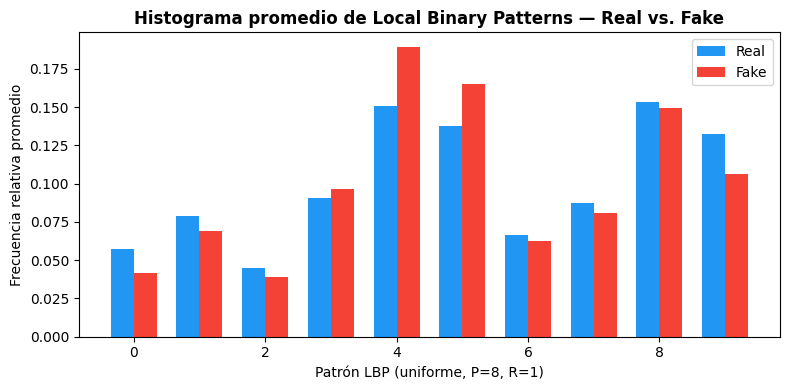

In [23]:
from skimage.feature import local_binary_pattern

def lbp_histogram(img, size=256, P=8, R=1):
    g = np.array(img.convert('L').resize((size, size)))
    lbp = local_binary_pattern(g, P, R, method='uniform')
    hist, _ = np.histogram(lbp, bins=np.arange(0, P + 3), density=True)
    return hist

N_LBP = 300
lbp_real = np.array([lbp_histogram(train[int(i)]['Image']) for i in tqdm(sample_real_idx[:N_LBP], desc='LBP Real')])
lbp_fake = np.array([lbp_histogram(train[int(i)]['Image']) for i in tqdm(sample_fake_idx[:N_LBP], desc='LBP Fake')])

mean_lbp_real = lbp_real.mean(axis=0)
mean_lbp_fake = lbp_fake.mean(axis=0)

x = np.arange(len(mean_lbp_real))
width = 0.35
plt.figure(figsize=(8, 4))
plt.bar(x - width / 2, mean_lbp_real, width, label='Real', color='#2196F3')
plt.bar(x + width / 2, mean_lbp_fake, width, label='Fake', color='#F44336')
plt.xlabel('Patrón LBP (uniforme, P=8, R=1)')
plt.ylabel('Frecuencia relativa promedio')
plt.title('Histograma promedio de Local Binary Patterns — Real vs. Fake', fontweight='bold')
plt.legend(); plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/11_lbp_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.6 Estadísticas a nivel de parche (16×16) — relevante para ViT-B/16

Un ViT-B/16 procesa la imagen (redimensionada típicamente a 224×224) como una secuencia de 14×14 = 196 parches de 16×16 px. Un histograma global de brillo/entropía puede diluir un artefacto que sea local a nivel de parche (p. ej. bordes de "tile" en modelos de difusión). Aquí se calcula la media y desviación estándar de intensidad **por parche**, y se mide la heterogeneidad entre parches dentro de cada imagen.

Parches Fake: 100%|██████████| 150/150 [00:02<00:00, 74.88it/s]
/tmp/ipykernel_846/3045582052.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([inter_patch_var_real, inter_patch_var_fake], labels=['Real', 'Fake'], patch_artist=True,


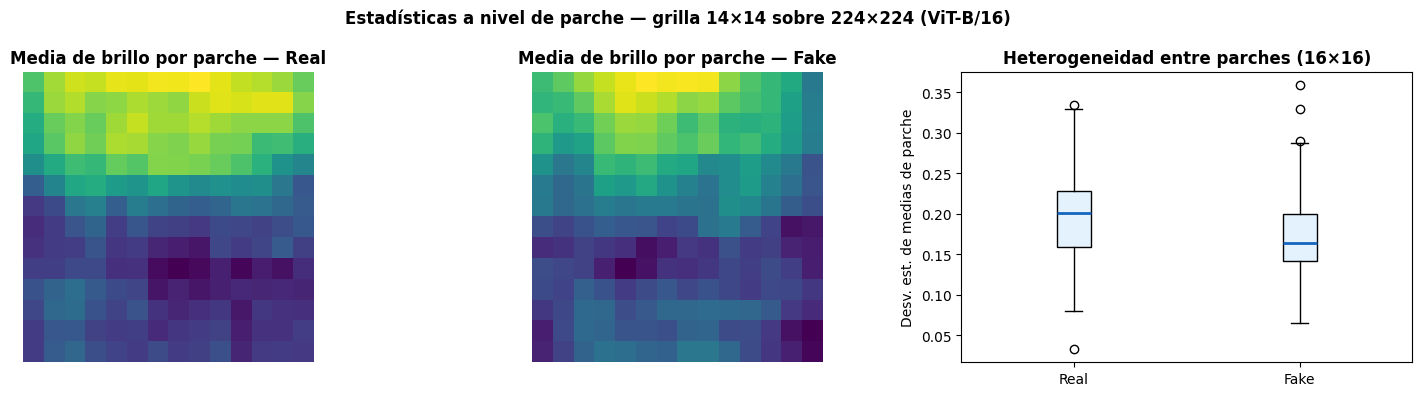

Heterogeneidad entre parches — Real: 0.1952 | Fake: 0.1711
Test t: t=3.933, p=0.0001 — Diferencia significativa


In [24]:
def patch_stats(img, img_size=224, patch=16):
    g = np.array(img.convert('L').resize((img_size, img_size)), dtype=np.float32) / 255.0
    n = img_size // patch
    means = np.zeros((n, n)); stds = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            block = g[i*patch:(i+1)*patch, j*patch:(j+1)*patch]
            means[i, j] = block.mean()
            stds[i, j] = block.std()
    return means, stds

N_PATCH = 150
means_real, means_fake = [], []
for i in tqdm(sample_real_idx[:N_PATCH], desc='Parches Real'):
    m, s = patch_stats(train[int(i)]['Image'])
    means_real.append(m)
for i in tqdm(sample_fake_idx[:N_PATCH], desc='Parches Fake'):
    m, s = patch_stats(train[int(i)]['Image'])
    means_fake.append(m)

means_real = np.stack(means_real)
means_fake = np.stack(means_fake)

# Heterogeneidad entre parches dentro de cada imagen (desv. est. de las medias de parche)
inter_patch_var_real = means_real.reshape(len(means_real), -1).std(axis=1)
inter_patch_var_fake = means_fake.reshape(len(means_fake), -1).std(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(means_real.mean(axis=0), cmap='viridis')
axes[0].set_title('Media de brillo por parche — Real', fontweight='bold'); axes[0].axis('off')
axes[1].imshow(means_fake.mean(axis=0), cmap='viridis')
axes[1].set_title('Media de brillo por parche — Fake', fontweight='bold'); axes[1].axis('off')
axes[2].boxplot([inter_patch_var_real, inter_patch_var_fake], labels=['Real', 'Fake'], patch_artist=True,
                boxprops=dict(facecolor='#E3F2FD'), medianprops=dict(color='#1565C0', linewidth=2))
axes[2].set_title('Heterogeneidad entre parches (16×16)', fontweight='bold')
axes[2].set_ylabel('Desv. est. de medias de parche')
plt.suptitle('Estadísticas a nivel de parche — grilla 14×14 sobre 224×224 (ViT-B/16)', fontweight='bold')
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/12_patch_level_stats.png', dpi=150, bbox_inches='tight')
plt.show()

t_stat, p_val = stats.ttest_ind(inter_patch_var_real, inter_patch_var_fake)
print(f"Heterogeneidad entre parches — Real: {inter_patch_var_real.mean():.4f} | Fake: {inter_patch_var_fake.mean():.4f}")
print(f"Test t: t={t_stat:.3f}, p={p_val:.4f} — {'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia significativa'}")

### 8.7 Espectro de potencia rebinneado a la grilla de parches (14×14)

Se reutilizan `ps_real` y `ps_fake` (espectros de potencia promedio de la sección 4.4, tamaño 256×256) y se reducen mediante *average pooling* a una grilla de 14×14, análoga a la resolución de tokens de un ViT-B/16, para inspeccionar si la diferencia Fake−Real observada en el espectro completo persiste a esa granularidad más gruesa.

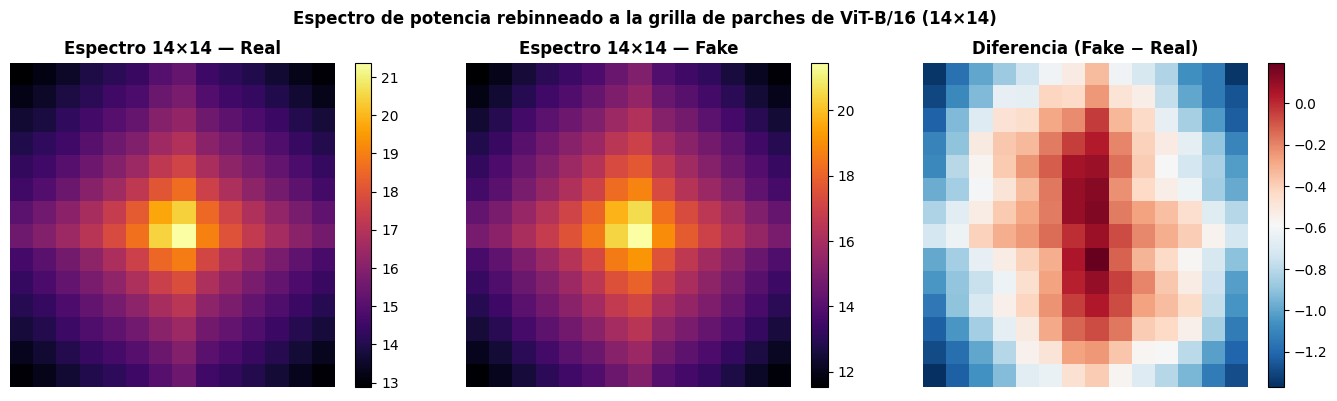

In [25]:
def rebin_spectrum_to_grid(ps, grid=14):
    """Reduce el espectro de potencia a una grilla grid×grid promediando bloques."""
    h, w = ps.shape
    bh, bw = h // grid, w // grid
    out = np.zeros((grid, grid))
    for i in range(grid):
        for j in range(grid):
            out[i, j] = ps[i*bh:(i+1)*bh, j*bw:(j+1)*bw].mean()
    return out

grid_real = rebin_spectrum_to_grid(ps_real, grid=14)
grid_fake = rebin_spectrum_to_grid(ps_fake, grid=14)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
im0 = axes[0].imshow(grid_real, cmap='inferno'); axes[0].set_title('Espectro 14×14 — Real', fontweight='bold'); axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046)
im1 = axes[1].imshow(grid_fake, cmap='inferno'); axes[1].set_title('Espectro 14×14 — Fake', fontweight='bold'); axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046)
diff_grid = grid_fake - grid_real
im2 = axes[2].imshow(diff_grid, cmap='RdBu_r'); axes[2].set_title('Diferencia (Fake − Real)', fontweight='bold'); axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046)
plt.suptitle('Espectro de potencia rebinneado a la grilla de parches de ViT-B/16 (14×14)', fontweight='bold')
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/13_patch_grid_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.8 Análisis desagregado por generador (`Label_B`)

La clase "Fake" agrupa 5 generadores distintos en partes iguales (ver Figura de la sección 2). Es importante verificar si las diferencias Real-vs-Fake reportadas antes son consistentes entre generadores o si un modelo corre el riesgo de aprender a detectar solo **un** generador específico y no generalizar a otros no vistos en entrenamiento.

Generador 5: 100%|██████████| 150/150 [00:02<00:00, 51.12it/s]


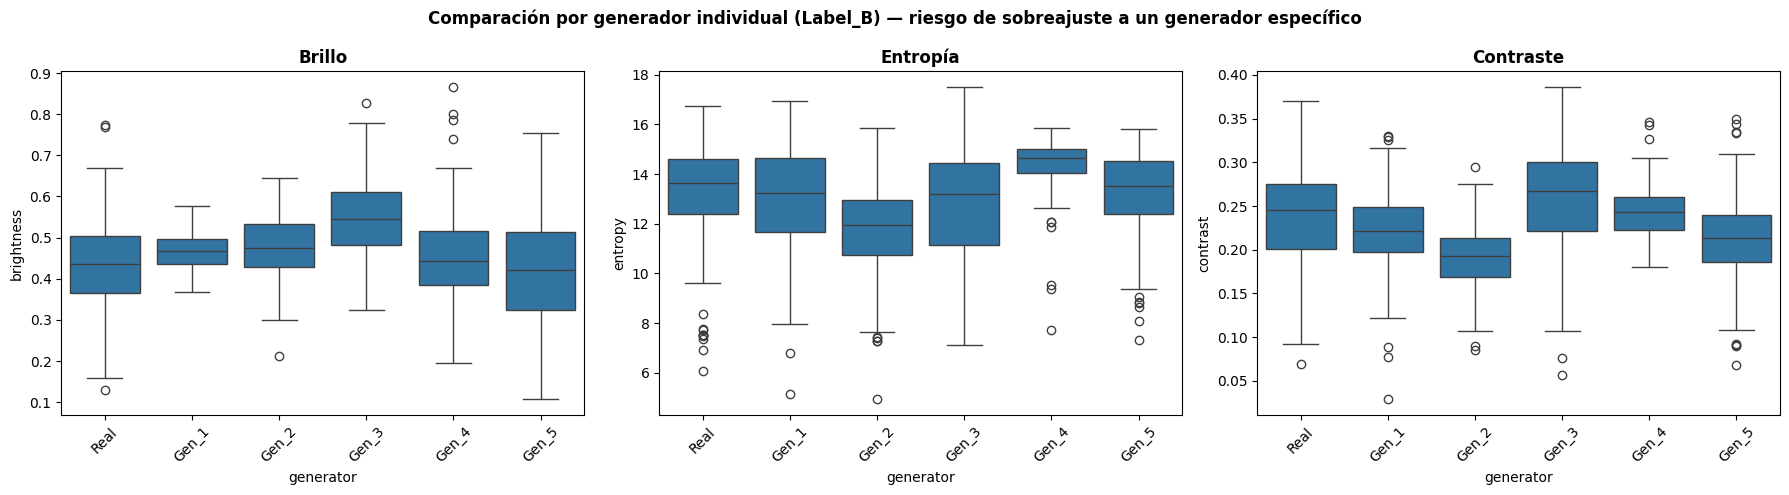

           brightness  entropy  contrast
generator                               
Real           0.4370  13.2055    0.2376
Gen_1          0.4681  12.9369    0.2209
Gen_2          0.4781  11.6637    0.1907
Gen_3          0.5453  12.7537    0.2591
Gen_4          0.4549  14.3934    0.2424
Gen_5          0.4194  13.2345    0.2130


In [26]:
labels_b = np.array(train["Label_B"])

N_GEN = 150
gen_stats = []
for gen_id in range(6):
    gen_idx = np.where(labels_b == gen_id)[0]
    gen_sample_idx = np.random.choice(gen_idx, min(N_GEN, len(gen_idx)), replace=False)
    for i in tqdm(gen_sample_idx, desc=f'Generador {gen_id}'):
        s = extract_stats(train[int(i)]['Image'])
        s['generator'] = 'Real' if gen_id == 0 else f'Gen_{gen_id}'
        gen_stats.append(s)

df_gen = pd.DataFrame(gen_stats)
gen_order = ['Real', 'Gen_1', 'Gen_2', 'Gen_3', 'Gen_4', 'Gen_5']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat, title in zip(axes, ['brightness', 'entropy', 'contrast'], ['Brillo', 'Entropía', 'Contraste']):
    sns.boxplot(data=df_gen, x='generator', y=feat, ax=ax, order=gen_order)
    ax.set_title(title, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
plt.suptitle('Comparación por generador individual (Label_B) — riesgo de sobreajuste a un generador específico',
             fontweight='bold')
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/14_per_generator_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(df_gen.groupby('generator')[['brightness', 'entropy', 'contrast']].mean().round(4).reindex(gen_order))

### 8.9 Verificación de fuga de datos entre splits (train / validation / test)

Complemento de la sección 8.1: se comparan los `Caption` únicos de cada split. Un solapamiento alto indicaría que la misma escena (y posiblemente variantes reales/sintéticas muy similares) aparece en más de una partición, lo cual infla artificialmente el desempeño reportado en validación/test si no se controla.

In [27]:
val_captions = set(ds['validation']['Caption'])
test_captions = set(ds['test']['Caption'])
train_captions = set(df['Caption'])

overlap_train_val = train_captions & val_captions
overlap_train_test = train_captions & test_captions
overlap_val_test = val_captions & test_captions

print(f"Captions únicos — train: {len(train_captions)} | validation: {len(val_captions)} | test: {len(test_captions)}")
print(f"\nSolapamiento train ∩ validation: {len(overlap_train_val)} "
      f"({len(overlap_train_val) / len(train_captions) * 100:.1f}% de train)")
print(f"Solapamiento train ∩ test: {len(overlap_train_test)} "
      f"({len(overlap_train_test) / len(train_captions) * 100:.1f}% de train)")
print(f"Solapamiento validation ∩ test: {len(overlap_val_test)} "
      f"({len(overlap_val_test) / len(val_captions) * 100:.1f}% de validation)")

Captions únicos — train: 6948 | validation: 1495 | test: 1500

Solapamiento train ∩ validation: 25 (0.4% de train)
Solapamiento train ∩ test: 31 (0.4% de train)
Solapamiento validation ∩ test: 7 (0.5% de validation)


### Síntesis — implicaciones para EfficientNet-B4 y ViT-B/16

- **Antes de entrenar cualquiera de los dos modelos**, resolver primero 8.1/8.9 (fuga de escenas entre clases y entre splits) y 8.2 (atajo de formato/compresión); de lo contrario, cualquier métrica de validación será optimista y poco fiable.
- **Para EfficientNet-B4**: las señales más prometedoras son nitidez (8.3), picos espectrales periódicos (8.4) y LBP (8.5), ya que esta arquitectura explota textura local de alta frecuencia.
- **Para ViT-B/16**: conviene inspeccionar variabilidad entre parches (8.6) y el espectro rebinneado a 14×14 (8.7), dado que el modelo tokeniza la imagen en esa grilla y puede ser menos sensible a textura fina uniforme que a patrones estructurados a nivel de parche.
- **En ambos casos**, repetir el EDA desagregado por generador (8.8) antes de dividir train/val/test para asegurar que cada generador esté representado en las tres particiones y evitar que el modelo aprenda a detectar un generador puntual en lugar de "imagen sintética" en general.

## 9. Características adicionales: confusores de resolución, forenses de bajo nivel y embeddings de una CNN preentrenada

Esta sección incorpora seis análisis adicionales, agrupados en tres frentes:

1. **Control de un confusor abierto**: la resolución nativa por clase y la compresibilidad normalizada por número de píxeles (bytes/px), que ayudan a interpretar si la diferencia de tamaño de archivo encontrada en la sección 5.2 se debe a resolución, a contenido, o a ambos.
2. **Descriptores forenses de bajo nivel** no explorados aún: correlación cruzada entre canales de color (huella de demosaicing/CFA), estadísticos de bloques DCT 8×8 (incl. Ley de Benford, estándar en forense de doble compresión JPEG) y *colorfulness* (Hasler–Süsstrunk).
3. **Separabilidad en el espacio de representación de una CNN preentrenada** (ResNet50/ImageNet): en vez de inventar más features de bajo nivel, se mide directamente qué tan separables son Real y Fake en el mismo tipo de espacio que usará el modelo final, mediante PCA, una distancia tipo Fréchet (FID) y un clasificador lineal simple sobre los embeddings.

### 9.1 Resolución nativa por clase

La sección 2 reportó resolución sobre una muestra sin desagregar por clase. Aquí se compara directamente Real vs. Fake, ya que una diferencia sistemática de resolución explicaría parte del efecto de tamaño de archivo visto en 5.2, y además interactúa con el resize a 380×380 (EfficientNet-B4) o 224×224 (ViT-B/16).

In [ ]:
N_RES = 500
res_real, res_fake = [], []
for i in tqdm(sample_real_idx[:N_RES], desc='Resolución Real'):
    res_real.append(train[int(i)]['Image'].size)  # (width, height)
for i in tqdm(sample_fake_idx[:N_RES], desc='Resolución Fake'):
    res_fake.append(train[int(i)]['Image'].size)

res_real = np.array(res_real)
res_fake = np.array(res_fake)

df_res = pd.DataFrame({
    'width': np.concatenate([res_real[:, 0], res_fake[:, 0]]),
    'height': np.concatenate([res_real[:, 1], res_fake[:, 1]]),
    'clase': ['Real'] * len(res_real) + ['Fake'] * len(res_fake)
})
df_res['area_mpx'] = df_res['width'] * df_res['height'] / 1e6

print(df_res.groupby('clase')[['width', 'height', 'area_mpx']].describe().round(3).T)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color_ in [('Real', '#2196F3'), ('Fake', '#F44336')]:
    subset = df_res[df_res['clase'] == label]
    axes[0].scatter(subset['width'], subset['height'], alpha=0.4, s=15, color=color_, label=label)
axes[0].set_xlabel('Ancho (px)'); axes[0].set_ylabel('Alto (px)')
axes[0].set_title('Resolución por clase', fontweight='bold'); axes[0].legend()

for label, color_ in [('Real', '#2196F3'), ('Fake', '#F44336')]:
    axes[1].hist(df_res[df_res['clase'] == label]['area_mpx'], bins=40, alpha=0.6, color=color_, label=label, density=True)
axes[1].set_xlabel('Área (megapíxeles)')
axes[1].set_title('Distribución de área — Real vs. Fake', fontweight='bold'); axes[1].legend()
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/15_resolution_by_class.png', dpi=150, bbox_inches='tight')
plt.show()

t_stat, p_val = stats.ttest_ind(df_res[df_res['clase'] == 'Real']['area_mpx'],
                                 df_res[df_res['clase'] == 'Fake']['area_mpx'])
print(f"Área (Mpx) — Real: {df_res[df_res['clase']=='Real']['area_mpx'].mean():.3f} | "
      f"Fake: {df_res[df_res['clase']=='Fake']['area_mpx'].mean():.3f}")
print(f"Test t: t={t_stat:.3f}, p={p_val:.4f} — {'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia significativa'}")

### 9.2 Compresibilidad normalizada (bytes por píxel)

Se combina tamaño de archivo y resolución en una sola métrica, `bytes_per_px = size_kb·1024 / (ancho·alto)`, que aísla la complejidad de textura del efecto de resolución detectado en 9.1.

In [ ]:
def inspect_bytes_full(img_dict):
    b = img_dict['bytes']
    im = PILImage.open(io.BytesIO(b))
    w, h = im.size
    size_kb = len(b) / 1024
    bpp = size_kb * 1024 / (w * h)
    return pd.Series({'width': w, 'height': h, 'size_kb': size_kb, 'bytes_per_px': bpp})

N_BPP = 800
sample_df2 = pd.concat([
    df[df['Label_A'] == 0].sample(min(N_BPP, (df['Label_A'] == 0).sum()), random_state=7),
    df[df['Label_A'] == 1].sample(min(N_BPP, (df['Label_A'] == 1).sum()), random_state=7),
]).copy()
sample_df2[['width', 'height', 'size_kb', 'bytes_per_px']] = sample_df2['Image'].apply(inspect_bytes_full)
sample_df2['clase'] = sample_df2['Label_A'].map({0: 'Real', 1: 'Fake'})

print(sample_df2.groupby('clase')['bytes_per_px'].describe().round(4))

In [ ]:
plt.figure(figsize=(7, 4))
for label, color_ in [('Real', '#2196F3'), ('Fake', '#F44336')]:
    subset = sample_df2[sample_df2['clase'] == label]
    plt.hist(subset['bytes_per_px'], bins=50, alpha=0.6, color=color_, label=label, density=True)
plt.xlabel('Bytes por píxel')
plt.title('Compresibilidad normalizada por resolución — Real vs. Fake', fontweight='bold')
plt.legend(); plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/16_bytes_per_pixel.png', dpi=150, bbox_inches='tight')
plt.show()

t_stat, p_val = stats.ttest_ind(sample_df2[sample_df2['clase'] == 'Real']['bytes_per_px'],
                                 sample_df2[sample_df2['clase'] == 'Fake']['bytes_per_px'])
print(f"Bytes/px — Real: {sample_df2[sample_df2['clase']=='Real']['bytes_per_px'].mean():.4f} | "
      f"Fake: {sample_df2[sample_df2['clase']=='Fake']['bytes_per_px'].mean():.4f}")
print(f"Test t: t={t_stat:.3f}, p={p_val:.4f} — {'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia significativa'}")

### 9.3 Correlación cruzada entre canales de color (huella de demosaicing/CFA)

Las cámaras reales capturan color mediante un filtro de mosaico (Bayer) y luego interpolan (demosaicing), lo que deja una correlación espacial característica y periódica entre los residuos de alta frecuencia de los canales R, G y B. Las imágenes generadas directamente en RGB no necesariamente reproducen ese patrón. Se calcula el residuo de cada canal frente a un suavizado 3×3 y la correlación de Pearson entre pares de canales.

In [ ]:
from scipy.ndimage import uniform_filter as _uniform_filter

def channel_crosscorr(img, size=256):
    arr = np.array(img.convert('RGB').resize((size, size)), dtype=np.float32)
    R, G, B = arr[..., 0], arr[..., 1], arr[..., 2]

    def hf(c):
        return c - _uniform_filter(c, size=3)

    rR, rG, rB = hf(R), hf(G), hf(B)

    def corr(a, b):
        return np.corrcoef(a.ravel(), b.ravel())[0, 1]

    return corr(rR, rG), corr(rG, rB), corr(rR, rB)

N_CFA = 200
cfa_real = np.array([channel_crosscorr(train[int(i)]['Image']) for i in tqdm(sample_real_idx[:N_CFA], desc='CFA Real')])
cfa_fake = np.array([channel_crosscorr(train[int(i)]['Image']) for i in tqdm(sample_fake_idx[:N_CFA], desc='CFA Fake')])

In [ ]:
labels_cc = ['R\u2194G', 'G\u2194B', 'R\u2194B']
fig, ax = plt.subplots(figsize=(7, 4))
positions_real = np.arange(3) - 0.15
positions_fake = np.arange(3) + 0.15
bp1 = ax.boxplot([cfa_real[:, k] for k in range(3)], positions=positions_real, widths=0.25,
                  patch_artist=True, boxprops=dict(facecolor='#90CAF9'))
bp2 = ax.boxplot([cfa_fake[:, k] for k in range(3)], positions=positions_fake, widths=0.25,
                  patch_artist=True, boxprops=dict(facecolor='#EF9A9A'))
ax.set_xticks(range(3)); ax.set_xticklabels(labels_cc)
ax.set_ylabel('Correlación entre residuos de alta frecuencia')
ax.set_title('Correlación cruzada entre canales (huella de demosaicing/CFA)', fontweight='bold')
ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ['Real', 'Fake'])
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/17_cfa_crosscorr.png', dpi=150, bbox_inches='tight')
plt.show()

for k, name in enumerate(labels_cc):
    t_stat, p_val = stats.ttest_ind(cfa_real[:, k], cfa_fake[:, k])
    print(f"{name}: Real={cfa_real[:,k].mean():.4f} | Fake={cfa_fake[:,k].mean():.4f} | "
          f"t={t_stat:.3f}, p={p_val:.4f} — {'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia significativa'}")

### 9.4 Estadísticos DCT en bloques 8×8 (Ley de Benford)

Como todo el dataset está almacenado en JPEG, el codificador real trabaja internamente en bloques de 8×8 mediante la Transformada Discreta del Coseno (DCT). Se calcula, por bloque, la energía de los coeficientes AC (excluyendo la componente DC) y el primer dígito significativo de dichos coeficientes, que en imágenes naturales de una sola compresión sigue aproximadamente la Ley de Benford — una prueba estándar en forense digital para detectar re-compresión o manipulación.

In [ ]:
from scipy.fftpack import dctn

def dct_block_stats(img, size=128, block=8):
    g = np.array(img.convert('L').resize((size, size)), dtype=np.float32)
    n = size // block
    ac_energy = []
    first_digits = []
    for i in range(n):
        for j in range(n):
            blk = g[i*block:(i+1)*block, j*block:(j+1)*block]
            d = dctn(blk, norm='ortho')
            ac = d.copy(); ac[0, 0] = 0
            ac_energy.append(np.sum(ac ** 2))
            nz = np.abs(ac[ac != 0])
            nz = nz[nz >= 1]
            if len(nz):
                fd = (nz // 10 ** np.floor(np.log10(nz))).astype(int)
                first_digits.extend(fd.tolist())
    return np.mean(ac_energy), first_digits

N_DCT = 60
energy_real, digits_real = [], []
energy_fake, digits_fake = [], []
for i in tqdm(sample_real_idx[:N_DCT], desc='DCT Real'):
    e, d = dct_block_stats(train[int(i)]['Image'])
    energy_real.append(e); digits_real.extend(d)
for i in tqdm(sample_fake_idx[:N_DCT], desc='DCT Fake'):
    e, d = dct_block_stats(train[int(i)]['Image'])
    energy_fake.append(e); digits_fake.extend(d)

In [ ]:
benford = np.array([np.log10(1 + 1 / d) for d in range(1, 10)])

def digit_hist(digits):
    digits = np.array(digits)
    counts = np.array([(digits == d).sum() for d in range(1, 10)])
    return counts / counts.sum()

hist_real = digit_hist(digits_real)
hist_fake = digit_hist(digits_fake)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(1, 10)
axes[0].bar(x - 0.2, hist_real, width=0.4, label='Real', color='#2196F3')
axes[0].bar(x + 0.2, hist_fake, width=0.4, label='Fake', color='#F44336')
axes[0].plot(x, benford, 'k--o', label='Ley de Benford')
axes[0].set_xlabel('Primer dígito significativo (coef. AC)'); axes[0].set_ylabel('Frecuencia relativa')
axes[0].set_title('Ley de Benford — coeficientes DCT 8×8', fontweight='bold'); axes[0].legend()

axes[1].hist(energy_real, bins=30, alpha=0.6, color='#2196F3', label='Real', density=True)
axes[1].hist(energy_fake, bins=30, alpha=0.6, color='#F44336', label='Fake', density=True)
axes[1].set_xlabel('Energía media de coeficientes AC por bloque 8×8')
axes[1].set_title('Energía DCT — Real vs. Fake', fontweight='bold'); axes[1].legend()
plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/18_dct_blocks.png', dpi=150, bbox_inches='tight')
plt.show()

chi2_real = np.sum((hist_real - benford) ** 2 / benford)
chi2_fake = np.sum((hist_fake - benford) ** 2 / benford)
print(f"Distancia chi-cuadrado a la Ley de Benford — Real: {chi2_real:.5f} | Fake: {chi2_fake:.5f} "
      f"(menor = más cercano a Benford = más compatible con una sola compresión JPEG natural)")

t_stat, p_val = stats.ttest_ind(energy_real, energy_fake)
print(f"\nEnergía DCT media — Real: {np.mean(energy_real):.2f} | Fake: {np.mean(energy_fake):.2f}")
print(f"Test t: t={t_stat:.3f}, p={p_val:.4f} — {'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia significativa'}")

### 9.5 Colorfulness (Hasler–Süsstrunk)

Métrica estándar de "viveza"/saturación de color, calculada a partir de las diferencias rojo-verde (`rg`) y amarillo-azul (`yb`) en el espacio RGB. Varios estudios de detección de imágenes sintéticas reportan que las imágenes generadas tienden a estar ligeramente más (o, según el generador, menos) saturadas que las fotografías reales.

In [ ]:
def colorfulness(img, size=256):
    arr = np.array(img.convert('RGB').resize((size, size)), dtype=np.float32)
    R, G, B = arr[..., 0], arr[..., 1], arr[..., 2]
    rg = R - G
    yb = 0.5 * (R + G) - B
    std_rg, std_yb = rg.std(), yb.std()
    mean_rg, mean_yb = rg.mean(), yb.mean()
    return np.sqrt(std_rg ** 2 + std_yb ** 2) + 0.3 * np.sqrt(mean_rg ** 2 + mean_yb ** 2)

N_COLOR = 400
color_real = [colorfulness(train[int(i)]['Image']) for i in tqdm(sample_real_idx[:N_COLOR], desc='Colorfulness Real')]
color_fake = [colorfulness(train[int(i)]['Image']) for i in tqdm(sample_fake_idx[:N_COLOR], desc='Colorfulness Fake')]

plt.figure(figsize=(7, 4))
plt.hist(color_real, bins=40, alpha=0.6, color='#2196F3', label='Real', density=True)
plt.hist(color_fake, bins=40, alpha=0.6, color='#F44336', label='Fake', density=True)
plt.xlabel('Colorfulness (Hasler\u2013S\u00fcsstrunk)')
plt.title('Saturación/viveza de color — Real vs. Fake', fontweight='bold')
plt.legend(); plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/19_colorfulness.png', dpi=150, bbox_inches='tight')
plt.show()

t_stat, p_val = stats.ttest_ind(color_real, color_fake)
print(f"Colorfulness media — Real: {np.mean(color_real):.2f} | Fake: {np.mean(color_fake):.2f}")
print(f"Test t: t={t_stat:.3f}, p={p_val:.4f} — {'Diferencia significativa' if p_val < 0.05 else 'Sin diferencia significativa'}")

### 9.6 Separabilidad en el espacio de embeddings de una CNN preentrenada (ResNet50/ImageNet)

En vez de seguir construyendo features de bajo nivel a mano, esta última prueba mide directamente qué tan separables son las clases en un espacio de representación del mismo tipo que usará el modelo final: se extraen embeddings de 2048 dimensiones de una ResNet50 preentrenada en ImageNet (sin fine-tuning), se proyectan a 2D con PCA para inspección visual, se calcula una distancia tipo Fréchet (el mismo principio que el FID usado para evaluar modelos generativos) entre las nubes Real y Fake, y se entrena un clasificador lineal simple sobre los embeddings crudos para obtener una cota empírica de separabilidad (AUC-ROC).

In [ ]:
!pip install torch torchvision -q

In [ ]:
import torch
import torchvision.transforms as T
from torchvision.models import resnet50, ResNet50_Weights

device = 'cuda' if torch.cuda.is_available() else 'cpu'
weights = ResNet50_Weights.IMAGENET1K_V2
resnet_model = resnet50(weights=weights)
resnet_model.fc = torch.nn.Identity()  # embedding de 2048-d, sin capa de clasificación
resnet_model.eval().to(device)

preprocess = weights.transforms()

def get_embeddings(images, batch_size=32):
    embs = []
    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch = images[i:i + batch_size]
            x = torch.stack([preprocess(im.convert('RGB')) for im in batch]).to(device)
            e = resnet_model(x).cpu().numpy()
            embs.append(e)
    return np.concatenate(embs, axis=0)

N_EMB = 300
imgs_real = [train[int(i)]['Image'] for i in tqdm(sample_real_idx[:N_EMB], desc='Cargando Real')]
imgs_fake = [train[int(i)]['Image'] for i in tqdm(sample_fake_idx[:N_EMB], desc='Cargando Fake')]

emb_real = get_embeddings(imgs_real)
emb_fake = get_embeddings(imgs_fake)
print("Embeddings extraídos:", emb_real.shape, emb_fake.shape)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
emb_all = np.concatenate([emb_real, emb_fake], axis=0)
emb_2d = pca.fit_transform(emb_all)
emb_2d_real = emb_2d[:len(emb_real)]
emb_2d_fake = emb_2d[len(emb_real):]

plt.figure(figsize=(7, 6))
plt.scatter(emb_2d_real[:, 0], emb_2d_real[:, 1], alpha=0.5, s=20, color='#2196F3', label='Real')
plt.scatter(emb_2d_fake[:, 0], emb_2d_fake[:, 1], alpha=0.5, s=20, color='#F44336', label='Fake')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var.)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var.)')
plt.title('Embeddings de ResNet50 (ImageNet) proyectados a 2D — Real vs. Fake', fontweight='bold')
plt.legend(); plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/20_resnet_embeddings_pca.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from scipy.linalg import sqrtm as _sqrtm

def frechet_distance(mu1, sigma1, mu2, sigma2):
    diff = mu1 - mu2
    covmean = _sqrtm(sigma1 @ sigma2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return diff @ diff + np.trace(sigma1 + sigma2 - 2 * covmean)

mu_r, mu_f = emb_real.mean(axis=0), emb_fake.mean(axis=0)
sigma_r, sigma_f = np.cov(emb_real, rowvar=False), np.cov(emb_fake, rowvar=False)
fid = frechet_distance(mu_r, sigma_r, mu_f, sigma_f)

centroid_dist = np.linalg.norm(mu_r - mu_f)
avg_intra_r = np.mean(np.linalg.norm(emb_real - mu_r, axis=1))
avg_intra_f = np.mean(np.linalg.norm(emb_fake - mu_f, axis=1))

print(f"Distancia de Fréchet (tipo FID) entre embeddings Real y Fake: {fid:.2f}")
print(f"Distancia entre centroides: {centroid_dist:.2f}")
print(f"Dispersión intra-clase — Real: {avg_intra_r:.2f} | Fake: {avg_intra_f:.2f}")
print(f"Razón distancia_centroides / dispersión_promedio: {centroid_dist / ((avg_intra_r + avg_intra_f) / 2):.3f} "
      f"(>1 sugiere clases más separadas entre sí que dispersas internamente)")

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

X = np.concatenate([emb_real, emb_fake], axis=0)
y = np.concatenate([np.zeros(len(emb_real)), np.ones(len(emb_fake))])

clf = LogisticRegression(max_iter=2000)
cv_scores = cross_val_score(clf, X, y, cv=5, scoring='roc_auc')

print(f"AUC-ROC (validación cruzada 5-fold) de regresión logística sobre embeddings de ResNet50: "
      f"{cv_scores.mean():.3f} \u00b1 {cv_scores.std():.3f}")
print("\nInterpretación: un AUC cercano a 0.5 indica que, en este espacio de representación genérico "
      "(ImageNet, sin fine-tuning), las clases son poco separables con un clasificador lineal simple; "
      "un AUC alto (>0.8) sugiere que ya existe señal fuerte explotable por una CNN, incluso antes de "
      "cualquier ajuste fino específico al problema.")

### Síntesis — sección 9

- **9.1–9.2** permiten desacoplar el efecto de resolución del de compresibilidad de contenido en el hallazgo de tamaño de archivo de la sección 5.2.
- **9.3 (CFA/demosaicing)** y **9.4 (DCT/Benford)** son descriptores forenses clásicos; su significancia (o falta de ella) indica si el proceso de generación deja o no una huella detectable a nivel de sensor/compresión, complementaria a la señal de textura ya identificada en la sección 5.
- **9.5 (colorfulness)** aporta una dimensión de color no cubierta por brightness/contrast/entropy.
- **9.6 (embeddings ResNet50)** es la prueba más directa de "aprendibilidad": el AUC-ROC de un clasificador lineal simple sobre embeddings genéricos da una cota inferior realista de lo que EfficientNet-B4 o ViT-B/16 deberían poder lograr como mínimo tras fine-tuning.